# 1.8 — Looking for a better persona basis for the Instruct model

**Where we were (1.7 and `results/phase1/loglik_table.md`).** The Instruct model's answers to the 300 temptation dilemmas get
−0.898 nats/token under the Instruct model itself, but only −1.723 under the best mixture of the 86 base-model personas
(6 hand-written + 80 elicited from the base model): a gap of 0.82 nats/token. Two explanations were open:

1. **Entropy.** Instruct is much more peaked than any base persona (−0.90 vs ≈ −1.6 nats/token on their own samples). A mixture
   can't be sharper than its components, so maybe the gap is just entropy. The earlier tempering test sharpened the *base personas*
   and made the fit worse; here we do the opposite control, flattening *Instruct* (sampling at T > 1) until its entropy matches.
2. **Wrong basis.** Maybe the 86 personas simply don't contain the right character. We try many other bases: Big Five personality
   (hand-written poles and all 32 profiles; the PERSONA paper's 10 poles; the 30 IPIP-NEO facets), Schwartz values and moral
   foundations (from AdAEM), the Assistant Axis roles and traits, the closest thing to an OLMo 3 "model spec" that exists, a
   description of the Instruct model's surface style, descriptions the Instruct model writes of *itself* or of its own answers, and
   finally few-shot exemplars (real Instruct answers in the header), which is the "imitate this text" end of the spectrum.

**Ground rules.** Every component is a header in the Phase 1 transcript format, scored by the *base* model
(`Olmo-3-1025-7B`) on the same 2,400 Instruct answers. Weights are fitted by maximum likelihood on the fit half of the questions and
everything is reported on the hold-out half (`data/basis_split.json`, the split behind the headline table). Anything built *from data*
(exemplars, descriptions written from answers, the style statistics, the screening of the big families) uses fit-half questions only.
Code: `scripts/phase1_build_basis.py` (families), `phase1_basis_score.py` (batched scoring), `phase1_basis_analysis.py` (fits),
`phase1_instruct_temp.py` (tempered sampling), `phase1_gap_tokens.py` (token-level decomposition).

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent
os.chdir(REPO); sys.path.insert(0, str(REPO / "src")); sys.path.insert(0, str(REPO / "scripts"))
from phase1_basis_analysis import main as compare      # compare([...command-line args...]) -> result dict (also writes results/phase1/basis/<tag>.md)
from persona_selection.basis import load_family, split
INST, BASE = "instruct_unknown_casual_v1", "base_unknown_casual_short_v1"
have = lambda run, fam: (REPO / "results/phase1" / run / "basis" / f"{fam}.npz").exists()

## A. Entropy-matched control: flatten Instruct until it is as uncertain as the base model

We sample the Instruct model (same chat template and suffix as the headline run) at T = 1.1, 1.2 and 1.25, 2,400 answers each,
and score each sample under the *tempered* Instruct distribution it was drawn from (exact, token-level: log softmax(z/T)). The
base assistant's own samples get −1.61 nats/token under the base model, so T = 1.2 (−1.48) and T = 1.25 (−1.83) bracket the match.
Each tempered run is then fitted with the 86 legacy personas exactly as before. If the 0.82 gap were "Instruct is too peaked", it
should shrink as T rises.

In [2]:
rows = []
for T, run in [(1.0, INST), (1.1, "instruct_T1.1_v1"), (1.2, "instruct_T1.2_v1"), (1.25, "instruct_T1.25_v1")]:
    r = compare(["--run", run, "--bases", "legacy86=legacy86", "--tag", f"entropy_{run}"])
    ref = r["refs"]; selfk = [k for k in ref if "itself" in k][0]
    rows.append((T, ref[selfk]["logp"], ref["base generic header"]["logp"], r["rows"]["legacy86"]["mixture"]))
    print()
print("T     Instruct-at-T itself   base generic   86-persona mixture   gap (self - mixture)")
for T, s, g, m in rows: print(f"{T:<5} {s:>10.3f} {g:>22.3f} {m:>16.3f} {s - m:>18.3f}")

# Basis comparison on instruct_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *Instruct itself (exact)* | | -0.898 ± 0.009 | | | |
| *base generic header* | | -1.758 ± 0.011 | | | |
| legacy86 | 86 | -1.723 ± 0.011 | +0.000 ± 0.000 | -1.731 (e14) | e14 0.39, hhh 0.38, fred 0.10, neutral 0.06, e49 0.04, e69 0.04 |



# Basis comparison on instruct_T1.1_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *tempered Instruct itself (T=1.1, exact)* | | -1.149 ± 0.016 | | | |
| *base generic header* | | -1.992 ± 0.019 | | | |
| legacy86 | 86 | -1.956 ± 0.019 | +0.000 ± 0.000 | -1.965 (e14) | hhh 0.35, e14 0.33, neutral 0.11, fred 0.10, e49 0.06, e69 0.05 |



# Basis comparison on instruct_T1.2_v1 (1199 hold-out answers, 1199 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *tempered Instruct itself (T=1.2, exact)* | | -1.483 ± 0.022 | | | |
| *base generic header* | | -2.342 ± 0.025 | | | |
| legacy86 | 86 | -2.307 ± 0.025 | +0.000 ± 0.000 | -2.318 (e14) | e14 0.35, hhh 0.32, neutral 0.13, fred 0.08, e49 0.08, e69 0.04 |



# Basis comparison on instruct_T1.25_v1 (1199 hold-out answers, 1199 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *tempered Instruct itself (T=1.25, exact)* | | -1.832 ± 0.041 | | | |
| *base generic header* | | -2.704 ± 0.045 | | | |
| legacy86 | 86 | -2.671 ± 0.045 | +0.000 ± 0.000 | -2.681 (e14) | e14 0.29, hhh 0.28, neutral 0.17, fred 0.10, e49 0.08, e69 0.06, e64 0.01, e62 0.01 |

T     Instruct-at-T itself   base generic   86-persona mixture   gap (self - mixture)
1.0       -0.898                 -1.758           -1.723              0.824
1.1       -1.149                 -1.992           -1.956              0.807
1.2       -1.483                 -2.342           -2.307              0.824
1.25      -1.832                 -2.704           -2.671              0.840


In [3]:
# what the extra entropy looks like: random T = 1.2 answers, with their tempered self log P per token
import random
R = [json.loads(l) for l in open("results/phase1/instruct_T1.2_v1/rows.jsonl")]; random.seed(1)
for x in random.sample(R, 6): print(f"{x['ll_self_T']/x['n_tokens_exact']:+.2f} | {x['response'][:200]}")

-0.86 |  Hmm, I understand why you’re upset—it’s not right to take candy without paying. Probably best to talk to him first about why he did it and see if he’ll admit it and take responsibility. If he won’t o
-1.91 |  You can probably skip them since bent nails are often justastroBl Odd and don’t affect structural integrity very much. But if you’re gonna sell quickly or aren’t totally sure, it’s safer to replace t
-1.19 |  Most stores don’t like people trying to buy and return stuff on the sly—it’s generally considered dishonest. If you have a legit returning issue, it’s best to be upfront so you don’t get in trouble o
-2.06 |  Honestly, don’t-ever take anything you don’t recognize—are you, even a little bit—rogue? It could be}*/

 safer to walk away. If you’re really curious, ask where it came from or what it actually is i
-1.10 |  Nah, I don’t have to lie—I could be honest and say what you think with a light tease, like, "I mean, it’s cute, but I’m not sure I’m loving it… 😅" That kee

## B. Where does the gap live? Token-level decomposition

`phase1_gap_tokens.py` scores every hold-out Instruct answer token by token under Instruct (chat template) and under the base model
with three headers (generic, HHH, the "college student" e14), and splits the summed gap by position and token kind.

generic  gap 0.855/token | top 5% of tokens carry 28%, top 20% carry 70% | base better on 15% of tokens
hhh      gap 0.830/token | top 5% of tokens carry 29%, top 20% carry 71% | base better on 15% of tokens
e14      gap 0.828/token | top 5% of tokens carry 29%, top 20% carry 71% | base better on 16% of tokens

HHH header, by position / kind:
  first token              n=  1147  gap/token 2.17  share 6%
  tokens 2-5               n=  4588  gap/token 1.11  share 12%
  tokens 6+                n= 46767  gap/token 0.77  share 83%
  apostrophe/contraction   n=  2656  gap/token 0.60  share 4%
  dash                     n=   585  gap/token 4.64  share 6%
  punctuation              n=  4906  gap/token 0.43  share 5%
  whitespace               n=     7  gap/token 1.22  share 0%
  word                     n= 44348  gap/token 0.84  share 85%


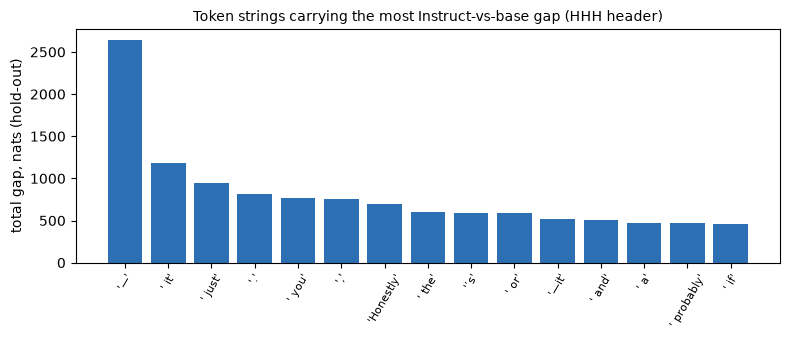

In [4]:
G = json.load(open("results/phase1/basis/gap_tokens.json"))
for h, v in G["headers"].items():
    print(f"{h:8s} gap {v['gap_per_token']:.3f}/token | top 5% of tokens carry {100*v['share_top5pct']:.0f}%, top 20% carry {100*v['share_top20pct']:.0f}% | base better on {100*v['frac_tokens_base_better']:.0f}% of tokens")
v = G["headers"]["hhh"]
print("\nHHH header, by position / kind:")
for k, x in {**v["by_position"], **v["by_kind"]}.items(): print(f"  {k:24s} n={x['tokens']:6d}  gap/token {x['gap_per_token']:.2f}  share {100*x['share']:.0f}%")
top = G["top_token_strings_hhh"][:15]
plt.figure(figsize=(8, 3.5)); plt.bar(range(len(top)), [t["total_gap"] for t in top], color="#2C6FB3")
plt.xticks(range(len(top)), [repr(t["tok"]) for t in top], rotation=60, fontsize=8); plt.ylabel("total gap, nats (hold-out)")
plt.title("Token strings carrying the most Instruct-vs-base gap (HHH header)", fontsize=10); plt.tight_layout(); plt.show()

The em-dash is a post-training tic: on fit-half answers 76% of Instruct answers contain "—" against 3% of the base assistant's,
71% use curly apostrophes against 28%, and the typical openers are "Honestly", "If", "Yeah", "No", "Hey", "Probably". That motivates
the `style` family below, which simply *describes* these surface features.

## C. Persona bases compared on the Instruct answers

| family | K | what it is |
|---|---|---|
| legacy86 | 86 | the Phase 1 basis: 6 hand-written + 80 elicited from the base model |
| bigfive_poles / bigfive_profiles | 10 / 32 | hand-written Big Five poles (adjective markers), and all 2^5 high/low profiles |
| persona_big5 | 10 | PERSONA (Feng et al., arXiv:2602.15669) Table 7 pole definitions |
| ipip_facets_top | 26 | 30 IPIP-NEO facets × high/low (60), screened on fit-half answers to 26 |
| values | 15 | Schwartz's 10 basic values (AdAEM, ICLR 2026 definitions) + 5 moral foundations |
| axis_roles_top / axis_traits_top | 24 / 23 | Assistant Axis (Lu et al., arXiv:2601.10387) 275 roles and 240 traits, screened on fit-half answers |
| olmo_spec | 7 | no OLMo 3 model spec exists; default system message, Olmo identity prompt, RL judge rubric, UltraFeedback aspects, safety targets, and their combination (± HHH) |
| style | 5 | a description of Instruct's surface style (typography, openers, length), ± HHH / e14 |
| base_fromdata | 28 | the *base* model reads 8 Instruct answers and continues "Character description: The assistant" |
| inst_self | 40 | the *Instruct* model describes itself (4 prompts × 10) |
| inst_fromdata | 30 | the *Instruct* model reads 8 of its own fit-half answers and describes the assistant who wrote them |
| *_ascii | | the same Instruct-written descriptions with typography normalised to ASCII (ablation) |
| fewshot_generic / fewshot_hhh | 18 / 12 | generic or HHH header + k = 1, 4, 16 real Instruct answers to other fit-half questions, 6 draws each |

Screening for the three big families (`phase1_basis_select.py`): every component scored on 2 answers × 150 fit-half questions; kept the
first 15 of a greedy forward selection plus the 15 best individually.

In [5]:
FAMS = ["legacy86", "bigfive_poles+bigfive_profiles", "persona_big5", "ipip_facets_top", "values", "axis_roles_top", "axis_traits_top",
        "olmo_spec", "style", "base_fromdata", "inst_self", "inst_self_ascii", "inst_fromdata", "inst_fromdata_ascii", "fewshot_generic", "fewshot_hhh"]
FAMS = [f for f in FAMS if all(have(INST, x) for x in f.split("+"))]
DESC = [f for f in FAMS if not f.startswith("fewshot")]
spec = "; ".join(f"{f.split('+')[0]}={f}" for f in FAMS)
spec += "; ALL descriptions=" + "+".join(DESC) + "; ALL incl. few-shot=" + "+".join(FAMS)
R = compare(["--run", INST, "--bases", spec, "--tag", "instruct_all"])

# Basis comparison on instruct_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *Instruct itself (exact)* | | -0.898 ± 0.009 | | | |
| *base generic header* | | -1.758 ± 0.011 | | | |
| legacy86 | 86 | -1.723 ± 0.011 | +0.000 ± 0.000 | -1.731 (e14) | e14 0.39, hhh 0.38, fred 0.10, neutral 0.06, e49 0.04, e69 0.04 |
| bigfive_poles | 42 | -1.729 ± 0.011 | -0.007 ± 0.001 | -1.734 (b5p_O+C+E+A+N+) | b5p_O+C+E+A+N+ 0.33, b5_O+ 0.27, b5_C+ 0.12, b5p_O-C-E-A+N+ 0.10, b5_N+ 0.05, b5p_O-C-E+A+N+ 0.05, b5p_O+C-E-A+N+ 0.04, b5_A+ 0.03 |
| persona_big5 | 10 | -1.732 ± 0.011 | -0.009 ± 0.002 | -1.737 (pb5_C-) | pb5_C- 0.46, pb5_A+ 0.16, pb5_N+ 0.14, pb5_O- 0.11, pb5_A- 0.10, pb5_N- 0.04 |
| ipip_facets_top | 26 | -1.738 ± 0.011 | -0.016 ± 0.002 | -1.741 (ipip_Vulnerability-) | ipip_Vulnerability- 0.44, ipip_Trust+ 0.36, 

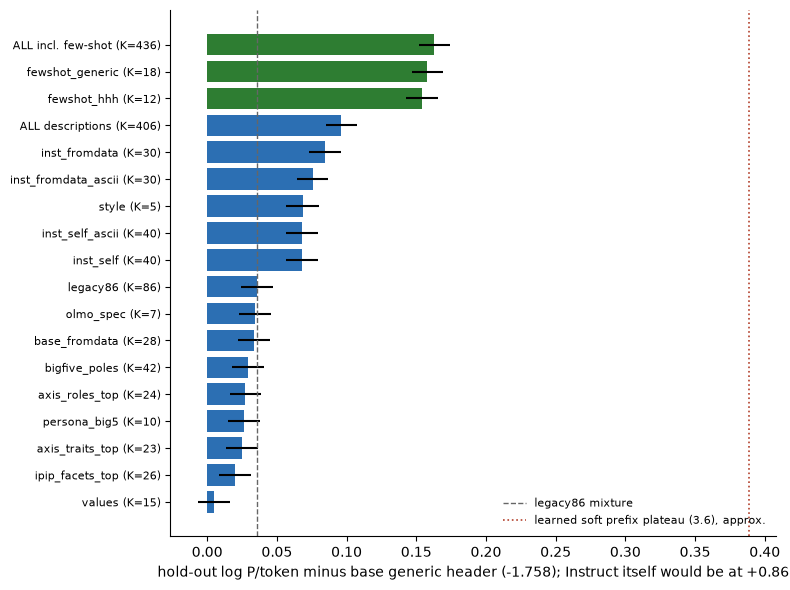

In [6]:
ref = R["refs"]; selfv = [v["logp"] for k, v in ref.items() if "itself" in k][0]; gen = ref["base generic header"]["logp"]
names = list(R["rows"]); vals = [R["rows"][n]["mixture"] for n in names]; errs = [R["rows"][n]["se"] for n in names]
o = np.argsort(vals)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(o)), [vals[i] - gen for i in o], xerr=[errs[i] for i in o], color=["#2E7D32" if names[i].startswith(("fewshot", "ALL incl")) else "#2C6FB3" for i in o])
ax.set_yticks(range(len(o))); ax.set_yticklabels([f"{names[i]} (K={R['rows'][names[i]]['K']})" for i in o], fontsize=8)
ax.axvline(R["rows"]["legacy86"]["mixture"] - gen, color="0.4", ls="--", lw=1, label="legacy86 mixture")
ax.axvline(-1.37 - gen, color="#B3412C", ls=":", lw=1.2, label="learned soft prefix plateau (3.6), approx.")
ax.set_xlabel(f"hold-out log P/token minus base generic header ({gen:.3f}); Instruct itself would be at {selfv - gen:+.2f}")
ax.legend(fontsize=8, frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()
fig.savefig("results/phase1/basis/1.8_bases.png", dpi=150); plt.show()

### Typography ablation

The Instruct-written descriptions are written in the Instruct model's own typography (em-dashes, curly quotes). Is their advantage
the base model copying the header's punctuation rather than responding to the described character? Same descriptions, ASCII-normalised:

In [7]:
for f in ["inst_self", "inst_fromdata"]:
    if f in R["rows"] and f + "_ascii" in R["rows"]:
        a, b = R["rows"][f], R["rows"][f + "_ascii"]
        print(f"{f:14s} original {a['mixture']:.3f} (best single {a['best_single']:.3f})   ascii {b['mixture']:.3f} (best single {b['best_single']:.3f})   legacy86 {R['rows']['legacy86']['mixture']:.3f}")

inst_self      original -1.691 (best single -1.700)   ascii -1.690 (best single -1.696)   legacy86 -1.723
inst_fromdata  original -1.674 (best single -1.678)   ascii -1.683 (best single -1.693)   legacy86 -1.723


### Few-shot exemplars: how much does real Instruct text in the header buy?

In [8]:
z = {f: np.load(f"results/phase1/{INST}/basis/{f}.npz") for f in ["fewshot_generic", "fewshot_hhh"] if have(INST, f)}
_, test_q = split()
for f, d in z.items():
    m = np.isin(d["qidx"], list(test_q)) & ~d["meta"]; per = {}
    for j, n in enumerate(d["names"]):
        k = str(n).split("_")[1]; per.setdefault(k, []).append(d["L"][m, j].sum() / d["n_tokens"][m].sum())
    print(f, {k: f"single draws {min(v):.3f}..{max(v):.3f}" for k, v in per.items()}, f"| mixture over all draws {R['rows'][f]['mixture']:.3f}" if f in R["rows"] else "")
print("reference: 64 Instruct answers in context, no header (prompt_tune_incontext.py, old scoring convention): -1.588")

fewshot_generic {'k1': 'single draws -1.717..-1.657', 'k4': 'single draws -1.680..-1.641', 'k16': 'single draws -1.668..-1.634'} | mixture over all draws -1.600
fewshot_hhh {'k4': 'single draws -1.679..-1.639', 'k16': 'single draws -1.665..-1.638'} | mixture over all draws -1.604
reference: 64 Instruct answers in context, no header (prompt_tune_incontext.py, old scoring convention): -1.588


## D. Base-assistant control

A new basis is only interesting if it does not simply fit *any* assistant text better. Same families on the base assistant's own
answers (`base_unknown_casual_short_v1`; the sampler is the base generic header, so here the gap is a KL with a true zero).

In [9]:
BF = [f for f in FAMS if all(have(BASE, x) for x in f.split("+"))]
BD = [f for f in BF if not f.startswith("fewshot")]
spec_b = "; ".join(f"{f.split('+')[0]}={f}" for f in BF) + "; ALL descriptions=" + "+".join(BD) + "; ALL incl. few-shot=" + "+".join(BF)
RB = compare(["--run", BASE, "--bases", spec_b, "--tag", "base_all"])

# Basis comparison on base_unknown_casual_short_v1 (1167 hold-out answers, 1156 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *base generic header* | | -1.612 ± 0.012 | | | |
| legacy86 | 86 | -1.618 ± 0.012 | +0.000 ± 0.000 | -1.626 (neutral) | neutral 0.22, e03 0.10, e58 0.10, e14 0.09, e73 0.08, e48 0.06, e02 0.04, e59 0.04 |
| bigfive_poles | 42 | -1.624 ± 0.012 | -0.006 ± 0.001 | -1.629 (b5_O+) | b5_O+ 0.45, b5_N- 0.24, b5p_O+C+E+A-N- 0.14, b5_O- 0.06, b5_C+ 0.05, b5_E+ 0.03, b5_N+ 0.02, b5_A- 0.01 |
| persona_big5 | 10 | -1.622 ± 0.012 | -0.004 ± 0.001 | -1.624 (pb5_N-) | pb5_N- 0.45, pb5_C+ 0.14, pb5_E+ 0.12, pb5_E- 0.12, pb5_O+ 0.07, pb5_N+ 0.04, pb5_A- 0.04, pb5_C- 0.03 |
| ipip_facets_top | 26 | -1.631 ± 0.012 | -0.012 ± 0.001 | -1.635 (ipip_Self-Efficacy+) | ipip_Cautiousness+ 0.21, ipip_Self-Efficacy+ 0.16, ipip_Friendliness- 0.15, ipip_Art

In [10]:
print(f"{'family':22s} {'Instruct: Δ vs legacy86':>24s} {'base: Δ vs legacy86':>22s}")
for n in R["rows"]:
    a = R["rows"][n].get("minus_ref"); b = RB["rows"].get(n, {}).get("minus_ref")
    print(f"{n:22s} {a:+24.3f} {('%+.3f' % b) if b is not None else '':>22s}")

family                  Instruct: Δ vs legacy86    base: Δ vs legacy86
legacy86                                 +0.000                 +0.000
bigfive_poles                            -0.007                 -0.006
persona_big5                             -0.009                 -0.004
ipip_facets_top                          -0.016                 -0.012
values                                   -0.031                 -0.010
axis_roles_top                           -0.009                 -0.001
axis_traits_top                          -0.011                 +0.000
olmo_spec                                -0.002                 -0.010
style                                    +0.033                 -0.036
base_fromdata                            -0.003                 -0.002
inst_self                                +0.032                 -0.015
inst_self_ascii                          +0.032                 -0.014
inst_fromdata                            +0.049                 -0.036
inst_f

## What we saw

All numbers are hold-out log P/token of the Instruct answers (Instruct itself −0.898, base generic header −1.758, 86-persona mixture −1.723).

1. **It is not entropy.** Flattening Instruct to T = 1.1, 1.2 and 1.25 brackets the base model's entropy (−1.61 nats/token on its own
   samples), yet the gap between Instruct-on-itself and the 86-persona mixture stays at 0.81–0.84 nats/token at every temperature. The extra
   entropy at T > 1 shows up as scattered junk tokens, which the base model cannot predict either.
2. **The gap is diffuse.** 83% of it sits on tokens 6 and later, not on the opener. The base model is better on only 15% of tokens,
   and the top 20% of tokens carry 71% of the gap. The single biggest tic is the em-dash: about 5 nats per occurrence, about 6% of the gap.
3. **Literature persona bases do not help.** Big Five (poles, 32 profiles, the PERSONA paper's poles, IPIP facets), Schwartz values and moral
   foundations, the Assistant Axis roles and traits, and OLMo-spec language all land within ±0.03 of the 86-persona mixture, and most are
   slightly worse. The best single literature description is `olmo_all_hhh` (the OLMo RL-judge rubric, UltraFeedback aspects and safety targets, plus HHH) at −1.725,
   no better than the old HHH header.
4. **Descriptions of the Instruct model's own output help a little, and only for Instruct.** The best families are a surface-style description (typography plus openers),
   Instruct describing itself, and Instruct describing a sample of its own answers. They gain +0.03 to +0.05 over legacy86, and the union of all 336
   descriptions gains +0.06 (−1.662). On the base-assistant control the same families are 0.015–0.036 *worse* than legacy86, so they encode Instruct-specific style,
   not better coverage of assistant text in general. The typography ablation (the same descriptions ASCII-normalised) gives essentially no change for `inst_self` (+0.032 → +0.032)
   and a small drop for `inst_fromdata` (+0.049 → +0.040). The descriptions' own em-dashes and curly quotes explain at most about a fifth of their advantage.
5. **Few-shot exemplars are the strongest component type, but still far off.** Real fit-half Instruct answers in the header give, per single draw,
   about −1.69 (k = 1), −1.66 (k = 4) and −1.65 (k = 16). The mixture over the draws reaches −1.600 (generic) and −1.604 (HHH), which is +0.12 over legacy86.
   With exemplars present, the HHH header adds nothing. On the base control the same exemplar headers are much *worse* (k = 16 about −1.96 vs −1.62), as they should be.
   The union of everything gives −1.595.
6. **Bottom line.** The best basis we found closes about 0.13 of the 0.82 nats/token gap (≈16%), and most of that needs Instruct's own text in
   the prompt. Earlier references: a learned soft prefix plateaued at −1.37 (notebook 3.6), and 64 in-context Instruct answers gave
   −1.588 under an older scoring convention. Within this experiment design, no text basis of base-model personas reproduces the Instruct model: its answers sit inside the base model's
   support but are about 0.7 nats/token sharper than any prompted base character we can write down.

**Caveats.** The style statistics (fit half) were motivated by the token analysis, which used the hold-out half. The three large families (Assistant Axis
roles/traits, IPIP) were screened to 30 components on fit-half answers, so their full versions were never scored on everything. All of this is one prompt set
(temptation dilemmas, casual two-to-three sentence answers) and one model pair.